# Đánh giá mô hình V2
Chạy từ thư mục ATTT bằng kernel `.venv`. Phần RLVS dùng dự đoán test đã lưu của lần train V2. Phần Hockey và video tự chọn chạy suy luận trực tiếp từ `best.pt`.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
from IPython.display import display, Video
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, RocCurveDisplay, ConfusionMatrixDisplay)


In [2]:
from pathlib import Path
DATA_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p/'train_v2/events.csv').is_file() and (p/'dataset').is_dir()), None)
if DATA_ROOT is None:
    raise FileNotFoundError('Mở thư mục ATTT làm workspace và chạy lại kernel.')
LABEL_DIR = DATA_ROOT/'train_v2'
SPLITS = LABEL_DIR/'splits'
RLVS = DATA_ROOT/'dataset'/'Real Life Violence Dataset'
OUT = LABEL_DIR/'runs'/'local_gpu_01'
OLD_BEST = None
EPOCHS, BATCH, ACCUM, SEED = 5, 1, 16, 42
import os
os.environ['TORCH_HOME'] = str(LABEL_DIR/'cache'/'torch')
cached_base = LABEL_DIR/'cache'/'hf'
BASE = str(cached_base) if (cached_base/'config.json').is_file() and (cached_base/'model.safetensors').is_file() else 'MCG-NJU/videomae-base-finetuned-kinetics'
print('Dữ liệu:', DATA_ROOT, '| Output:', OUT)

import hashlib, json, math, random, os, warnings
from functools import lru_cache
import cv2
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix

CONTACT = ['no_touch', 'touch', 'unclear']
SCALES = (.5, 1., 3.)
MEAN = np.array([.485,.456,.406], np.float32)
STD = np.array([.229,.224,.225], np.float32)
def filepath(raw):
    return str((DATA_ROOT / str(raw).replace(chr(92), '/')).resolve())

def file_hash(path):
    h = hashlib.sha256()
    with open(path,'rb') as stream:
        for chunk in iter(lambda:stream.read(1<<20), b''):
            h.update(chunk)
    return h.hexdigest()

@lru_cache(None)
def info(path):
    cap = cv2.VideoCapture(path)
    try:
        n, fps = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), cap.get(cv2.CAP_PROP_FPS)
        if n < 1 or not np.isfinite(fps) or fps <= 0:
            raise ValueError(f'Không đọc được video {path}')
        return n, fps
    finally:
        cap.release()



import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, SubsetRandomSampler
from torchvision.models.detection import keypointrcnn_resnet50_fpn, KeypointRCNN_ResNet50_FPN_Weights
from transformers import VideoMAEForVideoClassification
from tqdm.auto import tqdm
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
JOINTS=[0,5,6,7,8,9,10,11,12]
PAIR_DIM=2*len(JOINTS)*3
POSE_DIR=LABEL_DIR/'cache'/'pose'
POSE_DIR.mkdir(exist_ok=True,parents=True)

@lru_cache(1)
def detector():
    net=keypointrcnn_resnet50_fpn(weights=KeypointRCNN_ResNet50_FPN_Weights.DEFAULT,min_size=480,max_size=800)
    return net.cpu().eval()

def letterbox(rgb):
    h,w=rgb.shape[:2]
    scale=224/max(h,w)
    w2,h2=max(1,round(w*scale)),max(1,round(h*scale))
    img=np.full((224,224,3),114,np.uint8)
    x,y=(224-w2)//2,(224-h2)//2
    img[y:y+h2,x:x+w2]=cv2.resize(rgb,(w2,h2))
    return img

def indices_for(start,length,n,fps,training):
    edges=np.linspace(start*fps,(start+length)*fps,17)
    pos=np.random.uniform(edges[:-1],edges[1:]) if training else (edges[:-1]+edges[1:])/2
    return np.clip(pos.astype(int),0,n-1)

def detected_frames(images,ids,digest):
    # Cache normalized joints from original RGB, before augmentation.
    directory=POSE_DIR/digest
    directory.mkdir(exist_ok=True)
    found={}
    missing={}
    for i,img in zip(ids,images):
        i=int(i)
        file=directory/f'{i}.npy'
        if file.exists(): found[i]=np.load(file,allow_pickle=False)
        else: missing[i]=img
    keys=list(missing)
    for k in range(0,len(keys),2):
        group=keys[k:k+2]
        xs=[torch.from_numpy(missing[i]).permute(2,0,1).float()/255 for i in group]
        with torch.inference_mode(): preds=detector()(xs)
        for i,p in zip(group,preds):
            keep=(p['scores']>=.75)&(p['labels']==1)
            points=p['keypoints'][keep][:,JOINTS,:2].detach().cpu().numpy()
            scores=p['keypoints_scores'][keep][:,JOINTS].detach().cpu().numpy()
            h,w=missing[i].shape[:2]
            # Coordinates normalized in the original image. Third channel is joint availability.
            valid=scores>2
            arr=np.concatenate([points/np.array([w,h],np.float32),valid[...,None]],axis=-1).astype('float32')
            arr[~valid]=0
            np.save(directory/f'{i}.npy',arr)
            found[i]=arr
    return [found[int(i)] for i in ids]

def pair_sequence(detections):
    sequence=np.zeros((len(detections),2,len(JOINTS),3),np.float32)
    previous=None
    for j,people in enumerate(detections):
        if len(people)!=2: continue
        # Shoulders anchor identity. At least one visible wrist on one person.
        if not people[:,1:3,2].all() or not people[:,5:7,2].any(): continue
        centers=people[:,1:3,:2].mean(axis=1)
        if previous is None:
            order=np.argsort(centers[:,0])
        else:
            d1=np.linalg.norm(centers-previous,axis=1).sum()
            d2=np.linalg.norm(centers[::-1]-previous,axis=1).sum()
            if abs(d1-d2)<.025 or min(d1,d2)>.65: continue
            order=[0,1] if d1<d2 else [1,0]
        sequence[j]=people[order]
        previous=centers[order]
    return sequence

def read_window(path,start,length,digest,with_pose=True,training=False):
    n,fps=info(path)
    ids=indices_for(start,length,n,fps,training)
    cap=cv2.VideoCapture(path)
    images=[]
    try:
        for i in ids:
            cap.set(cv2.CAP_PROP_POS_FRAMES,int(i))
            ok,bgr=cap.read()
            if not ok:
                cap.release()
                cap=cv2.VideoCapture(path)
                for _ in range(int(i)+1):
                    ok,bgr=cap.read()
                    if not ok: break
            if not ok: raise ValueError(f'Lỗi frame {i}: {path}')
            images.append(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB))
    finally: cap.release()
    pairs=pair_sequence(detected_frames(images,ids,digest)) if with_pose else np.zeros((16,2,len(JOINTS),3),np.float32)
    rgb=np.stack([letterbox(img) for img in images])
    if training and random.random()<.5:
        rgb=rgb[:,:,::-1].copy()
        pairs[...,0]=np.where(pairs[...,2]>0,1-pairs[...,0],0)
        pairs=pairs[:,:,[0,2,1,4,3,6,5,8,7],:]
    if training and random.random()<.5: pairs=pairs[:,::-1].copy()
    rgb=(rgb.astype('float32')/255-MEAN)/STD
    return torch.from_numpy(rgb).permute(0,3,1,2),torch.from_numpy(pairs.reshape(16,PAIR_DIM).copy()),ids



class ContactVideoMAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.video=VideoMAEForVideoClassification.from_pretrained(BASE,num_labels=2,ignore_mismatched_sizes=True)
        self.pose=nn.GRU(PAIR_DIM,64,batch_first=True,bidirectional=True)
        self.contact=nn.Sequential(nn.Linear(self.video.config.hidden_size+128,128),nn.GELU(),nn.Dropout(.2),nn.Linear(128,3))
        self.action_pose=nn.Linear(128,2,bias=False)
        nn.init.zeros_(self.action_pose.weight)
    def forward(self,x,g):
        tokens=self.video.videomae(pixel_values=x).last_hidden_state
        pooled=self.video.fc_norm(tokens.mean(1)) if self.video.fc_norm is not None else tokens[:,0]
        action=self.video.classifier(pooled)
        swapped=g.reshape(len(g),16,2,-1).flip(2).reshape_as(g)
        _,h=self.pose(torch.cat([g,swapped],0))
        encoded=h.transpose(0,1).reshape(2*len(g),128)
        correction=self.action_pose(encoded.reshape(2,len(g),128).mean(0))
        action=action+correction*pose_quality(g).unsqueeze(1)
        logits=self.contact(torch.cat([pooled.repeat(2,1),encoded],1))
        return action,logits.reshape(2,len(g),3).mean(0)



def pose_quality(g):
    seen=g.abs().sum(-1)>0
    return (seen.float().mean(1)>=.5)&seen[:,5:11].any(1)



def decide(pa,pc,quality,policy):
    if pa<policy['action_threshold']: return 'normal'
    if (policy['contact_ready'] and quality and int(np.argmax(pc))==1
        and pc[1]>=policy['touch_threshold']): return 'fight'
    return 'suspected'



Dữ liệu: D:\TaiLieu\2026-2027\ATTT | Output: D:\TaiLieu\2026-2027\ATTT\train_v2\runs\local_gpu_01


In [3]:
policy = json.loads((OUT/'policy.json').read_text())
ck = torch.load(OUT/'best.pt', map_location='cpu', weights_only=True,mmap=True)
net = ContactVideoMAE()
net.load_state_dict(ck['model'], strict=True)
net.to(device).eval()
print('Checkpoint:', OUT/'best.pt', '| Epoch:', ck['epoch'], '| Thiết bị:', device)
del ck
print('Ngưỡng cảnh báo:', policy['action_threshold'], '| Xác nhận tiếp xúc:', policy['contact_ready'])
display(pd.Series({'Kiến trúc':'VideoMAE-base + GRU pose, hai đầu phân loại','Đầu vào':'16 frame RGB letterbox 224×224','Cửa sổ sự kiện (giây)':str(SCALES),'Huấn luyện':'AdamW, batch 1, tích lũy 16, fine-tune block cuối','Số tham số':sum(p.numel() for p in net.parameters()),**{s:len(pd.read_csv(SPLITS/f'rlvs_{s}.csv')) for s in ('train','val','test')}}).to_frame('Cấu hình V2'))

Checkpoint: D:\TaiLieu\2026-2027\ATTT\train_v2\runs\local_gpu_01\best.pt | Epoch: 2 | Thiết bị: cuda
Ngưỡng cảnh báo: 0.49999999999999994 | Xác nhận tiếp xúc: False


,Cấu hình V2
Kiến trúc,"VideoMAE-base + GRU pose, hai đầu phân loại"
Đầu vào,16 frame RGB letterbox 224×224
Cửa sổ sự kiện (giây),"(0.5, 1.0, 3.0)"
Huấn luyện,"AdamW, batch 1, tích lũy 16, fine-tune block cuối"
Số tham số,86390277
train,1414
val,310
test,287


## Lịch sử validation và hiệu quả trên RLVS
Mỗi video test đóng góp một dự đoán ở dòng `base`. Các cửa sổ gắn nhãn bổ sung được phân tích riêng theo tình huống.

RLVS test · 287 video


,action_f1,contact_macro_f1,selection
epoch,,,
1,0.970297,0.626263,0.798280
2,0.990033,0.707937,0.848985
3,0.990033,0.707937,0.848985
4,0.990033,0.707937,0.848985
5,0.990033,0.707937,0.848985


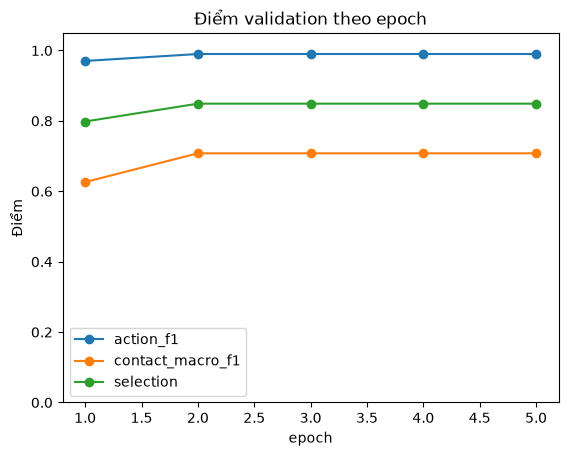

,Điểm
accuracy,0.986063
precision,0.986111
recall,0.986111
F1,0.986111
AUC,0.999272


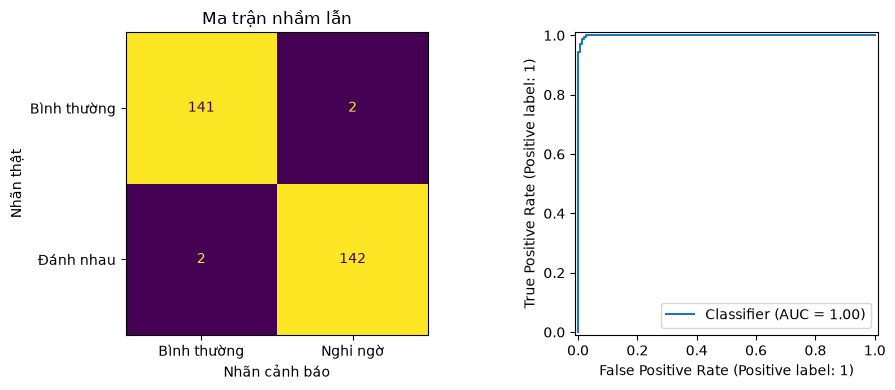

,clip,Nhãn thật,Nhãn cảnh báo,p_action
21,NV_256.mp4,Bình thường,Nghi ngờ đánh nhau,0.592784
59,NV_500.mp4,Bình thường,Nghi ngờ đánh nhau,0.692122
194,V_398.mp4,Đánh nhau,Bình thường,0.492066
199,V_43.mp4,Đánh nhau,Bình thường,0.431285


,scenario,sources,windows,false_logs,missed,review_strikes,fight_strikes
0,arm_overlap,1,2,0,0,0,0
2,body_overlap,1,2,0,0,0,0
3,fast_strike,1,3,0,0,3,0
4,grappling,1,3,0,0,3,0
5,hand_gesture,1,2,0,0,0,0


In [4]:
history = pd.read_json(OUT/'history.json').set_index('epoch')
display(history)
history.plot(marker='o', ylim=(0,1.05), title='Điểm validation theo epoch', ylabel='Điểm')
plt.show()
test = pd.read_csv(OUT/'test_predictions.csv')
rlvs = test[test.scenario.eq('base')].copy()
def evaluate(df, name):
    y, p = df.y, df.p_action
    pred = p >= policy['action_threshold']
    print(name, '·', len(df), 'video')
    display(pd.Series(dict(accuracy=accuracy_score(y,pred), precision=precision_score(y,pred,zero_division=0),
        recall=recall_score(y,pred,zero_division=0), F1=f1_score(y,pred,zero_division=0), AUC=roc_auc_score(y,p))).to_frame('Điểm'))
    fig, axes = plt.subplots(1,2,figsize=(10,4))
    ConfusionMatrixDisplay.from_predictions(y,pred,display_labels=['Bình thường','Đánh nhau'],ax=axes[0],colorbar=False)
    axes[0].set(xlabel='Nhãn cảnh báo',ylabel='Nhãn thật',title='Ma trận nhầm lẫn')
    axes[0].set_xticks([0,1],['Bình thường','Nghi ngờ'])
    RocCurveDisplay.from_predictions(y,p,ax=axes[1])
    fig.tight_layout()
    plt.show()
    errors = df.loc[pred.ne(y), ['path','y','p_action']].copy()
    errors['clip'] = errors.path.map(lambda x: Path(x).name)
    errors['Nhãn thật']=errors.y.map({0:'Bình thường',1:'Đánh nhau'})
    errors['Nhãn cảnh báo']=(errors.p_action >= policy['action_threshold']).map({True:'Nghi ngờ đánh nhau',False:'Bình thường'})
    display(errors[['clip','Nhãn thật','Nhãn cảnh báo','p_action']].head(10))
evaluate(rlvs, 'RLVS test')
display(pd.read_csv(OUT/'test_summary.csv').query("scenario != 'base'")[['scenario','sources','windows','false_logs','missed','review_strikes','fight_strikes']])

## Test chéo trên Hockey Fights
Mặc định đánh giá toàn bộ video. Có thể đặt PER_CLASS để chạy thử một mẫu cân bằng, seed 42. Dùng 16 frame mỗi video và cùng chế độ bỏ pose như các clip `base` của RLVS.

Hockey Fights · 1000 video


,Điểm
accuracy,0.518000
precision,0.509202
recall,0.996000
F1,0.673884
AUC,0.963202


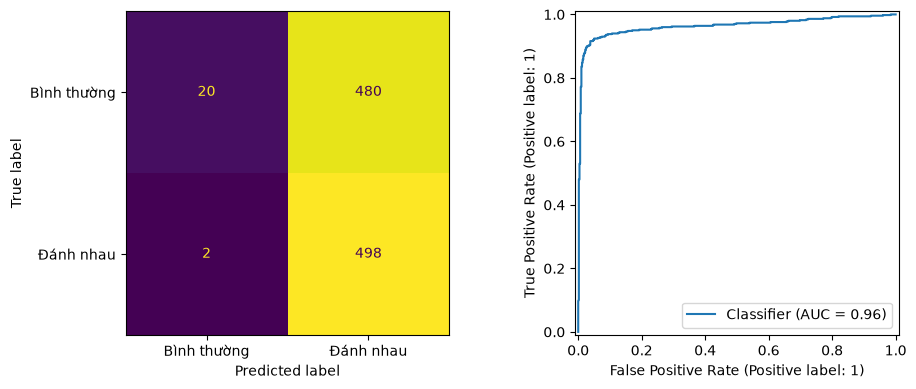

,clip,Nhãn thật,Nhãn cảnh báo,p_action
254,fi32_xvid.avi,Đánh nhau,Bình thường,0.499849
317,fi387_xvid.avi,Đánh nhau,Bình thường,0.461093
500,no100_xvid.avi,Bình thường,Nghi ngờ đánh nhau,0.504928
501,no101_xvid.avi,Bình thường,Nghi ngờ đánh nhau,0.634826
502,no102_xvid.avi,Bình thường,Nghi ngờ đánh nhau,0.705430
503,no103_xvid.avi,Bình thường,Nghi ngờ đánh nhau,0.637793
504,no104_xvid.avi,Bình thường,Nghi ngờ đánh nhau,0.555450
505,no105_xvid.avi,Bình thường,Nghi ngờ đánh nhau,0.723016
506,no106_xvid.avi,Bình thường,Nghi ngờ đánh nhau,0.636918
507,no107_xvid.avi,Bình thường,Nghi ngờ đánh nhau,0.629234


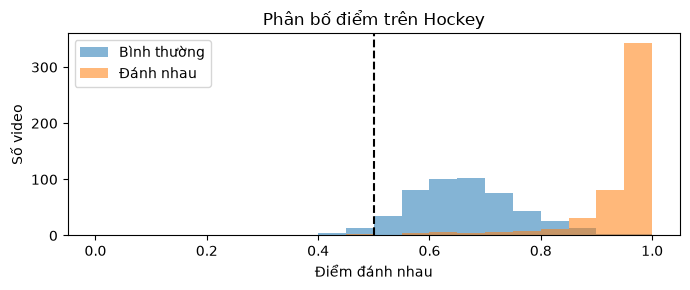

In [5]:
PER_CLASS = None
hockey_rows = []
for prefix, label in [('fi',1), ('no',0)]:
    paths = sorted((DATA_ROOT/'dataset/Hockey').glob(prefix+'*.avi'))
    if PER_CLASS is not None:
        paths = random.Random(SEED).sample(paths, PER_CLASS)
    for path in paths:
        n, fps = info(str(path))
        x, g, _ = read_window(str(path),0,n/fps,'',with_pose=False)
        with torch.inference_mode(), torch.autocast('cuda',dtype=torch.float16,enabled=device.type=='cuda'):
            a, _ = net(x[None].to(device),g[None].to(device))
        hockey_rows.append(dict(path=str(path), y=label,p_action=a.float().softmax(-1)[0,1].item()))
evaluate(pd.DataFrame(hockey_rows), 'Hockey Fights')
hockey = pd.DataFrame(hockey_rows)
fig, ax = plt.subplots(figsize=(7,3))
for label, name in [(0,'Bình thường'),(1,'Đánh nhau')]:
    ax.hist(hockey.loc[hockey.y==label,'p_action'],bins=np.linspace(0,1,21),alpha=.55,label=name)
ax.axvline(policy['action_threshold'],color='black',ls='--')
ax.set(xlabel='Điểm đánh nhau',ylabel='Số video',title='Phân bố điểm trên Hockey')
ax.legend()
plt.tight_layout()
plt.show()

## So sánh hai tập test: RLVS và Hockey
Mỗi video đóng góp một dự đoán. Cả hai tập dùng ngưỡng hành động đã chọn trên validation RLVS. Lớp dương là đánh nhau.

In [ ]:
from sklearn.metrics import confusion_matrix

def compare_tests(tables):
    rows = []
    for name, df in tables:
        y, score = df.y, df.p_action
        pred = score >= policy['action_threshold']
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        rows.append([name, len(df), fp, fn, accuracy_score(y,pred), precision_score(y,pred,zero_division=0),
                     recall_score(y,pred,zero_division=0), f1_score(y,pred,zero_division=0), roc_auc_score(y,score)])
    return pd.DataFrame(rows, columns=['Tập test','Video','Báo nhầm','Bỏ sót','Accuracy','Precision','Recall','F1','ROC AUC']).set_index('Tập test')

comparison = compare_tests([('RLVS', rlvs), ('Hockey', hockey)])
display(comparison.round(4))

,Video,Báo nhầm,Bỏ sót,Accuracy,Precision,Recall,F1,ROC AUC
Tập test,,,,,,,,
RLVS,287,2,2,0.9861,0.9861,0.9861,0.9861,0.9993
Hockey,1000,480,2,0.5180,0.5092,0.9960,0.6739,0.9632


## Demo video tự chọn và bốn clip KO
Đổi `VIDEOS` thành đường dẫn video của bạn. Mỗi đoạn được quét ở nhiều độ dài, bước trượt 0,2 giây. Bảng hiển thị cửa sổ có điểm đánh nhau cao nhất. Dùng `windows` để xem kết quả từng cửa sổ. Khi nhánh tiếp xúc chưa được bật, cảnh báo ở mức nghi ngờ.

Bốn video KO dùng nhãn thật cấp clip theo mô tả của người dùng. Bảng KO dùng cảnh báo cao nhất trong các cửa sổ; bảng RLVS/Hockey dùng dự đoán cả clip như khi tính chỉ số test. Dải màu biểu diễn quyết định theo đoạn. Chưa có nhãn thật theo từng frame.

In [6]:
@torch.inference_mode()
def scan_video(path,step_s=.2):
    net.eval()
    path=str(Path(path).resolve())
    n,fps=info(path);duration=n/fps;digest=file_hash(path)
    rows=[]
    for length in sorted({min(w,duration) for w in SCALES}):
        last=duration-length
        starts=np.unique(np.append(np.arange(0,last,step_s),last))
        for start in starts:
            x,g,_=read_window(path,start,length,digest)
            with torch.autocast('cuda',dtype=torch.float16,enabled=device.type=='cuda'):
                a,c=net(x[None].to(device),g[None].to(device))
            pa=a.softmax(-1)[0,1].item();pc=c.softmax(-1)[0].cpu().numpy()
            ok=pose_quality(g[None]).item()
            rows.append(dict(path=path,start_s=start,end_s=start+length,p_action=pa,p_touch=pc[1],
                             p_unclear=pc[2],pose_ok=ok,decision=decide(pa,pc,ok,policy)))
    return pd.DataFrame(rows)


import subprocess
import tempfile

@torch.inference_mode()
def base_score(path, start, length):
    x,g,_ = read_window(str(path),start,length,'',with_pose=False)
    with torch.autocast('cuda',dtype=torch.float16,enabled=device.type=='cuda'):
        a,_ = net(x[None].to(device),g[None].to(device))
    return a.float().softmax(-1)[0,1].item()

def present(path, rows, expected=None, clip_probability=None):
    path = Path(path)
    n,fps = info(str(path))
    times = np.arange(n)/fps
    scores = np.zeros(n)
    labels = np.full(n,'normal',dtype=object)
    for r in rows.itertuples():
        mask = (times>=r.start_s)&(times<r.end_s)&(r.p_action>=scores)
        scores[mask],labels[mask] = r.p_action,r.decision
    truth = expected or 'Chưa gán'
    names = {'normal':'Bình thường','suspected':'Nghi ngờ đánh nhau','fight':'Đánh nhau'}
    colors = {'normal':'#167457','suspected':'#ab5300','fight':'#ab263f'}
    alert = next((k for k in ('fight','suspected') if k in labels),'normal')
    if clip_probability is not None:
        alert = 'suspected' if clip_probability >= policy['action_threshold'] else 'normal'
    outcome = 'Chưa đối chiếu' if not expected else {('Đánh nhau',True):'Phát hiện đúng',
        ('Đánh nhau',False):'Bỏ sót',('Bình thường',True):'Báo nhầm',('Bình thường',False):'Đúng bình thường'}[truth,alert!='normal']
    display(pd.DataFrame([[path.name,truth,names[alert],outcome]], columns=['Video','Nhãn thật (clip)','Nhãn cảnh báo','Đối chiếu']).set_index('Video'))
    fig,(ax,strip)=plt.subplots(2,1,figsize=(10,4),sharex=True,layout='constrained',gridspec_kw={'height_ratios':[4,1]})
    edges=np.arange(n+1)/fps
    ax.stairs(scores*100,edges,color='#255db1',linewidth=2,label='Điểm cửa sổ')
    ax.axhline(100*policy['action_threshold'],ls='--',color='#525252',label=f"Ngưỡng {policy['action_threshold']:.0%}")
    ax.set(title=f'{path.name}  ·  Nhãn thật: {truth}  ·  {outcome}',ylabel='Điểm (%)',ylim=(-3,103),yticks=[0,25,50,75,100])
    ax.legend(fontsize=9); ax.grid(axis='y',alpha=.2)
    bounds=np.r_[0,np.flatnonzero(labels[1:]!=labels[:-1])+1,n]
    for a,b in zip(bounds[:-1],bounds[1:]):
        strip.axvspan(edges[a],edges[b],color=colors[labels[a]])
    from matplotlib.patches import Patch
    strip.legend(handles=[Patch(color=colors[k],label=names[k]) for k in names if k in labels],loc='upper left',bbox_to_anchor=(0,-.9),frameon=False,ncol=3)
    strip.set(xlabel='Thời gian (giây)',ylabel='Cảnh báo',yticks=[],xlim=(0,n/fps))
    plt.show()
    from PIL import Image,ImageDraw,ImageFont
    font=ImageFont.truetype(str(Path(os.environ['WINDIR'])/'Fonts/segoeui.ttf'),17)
    with tempfile.TemporaryDirectory() as tmp:
        raw, mp4 = Path(tmp)/'frames.avi', Path(tmp)/'demo.mp4'
        cap = cv2.VideoCapture(str(path))
        w,h = cap.get(3),cap.get(4)
        size = (480,max(2,int(480*h/w)//2*2))
        writer = cv2.VideoWriter(str(raw),cv2.VideoWriter_fourcc(*'MJPG'),fps,size)
        try:
            if not writer.isOpened(): raise RuntimeError('Không tạo được video minh họa')
            for i,score in enumerate(scores):
                ok,frame=cap.read()
                if not ok: break
                frame=cv2.resize(frame,size)
                image=Image.fromarray(cv2.cvtColor(frame,cv2.COLOR_BGR2RGB))
                draw=ImageDraw.Draw(image)
                draw.rectangle((0,0,size[0],52),fill='#111827')
                draw.text((8,2),f'Nhãn thật (clip): {truth}',font=font,fill='white')
                draw.text((8,26),f'Cảnh báo (đoạn): {names[labels[i]]} · {score:.0%}',font=font,fill='#a2f0c8' if labels[i]=='normal' else '#ffcc81')
                writer.write(cv2.cvtColor(np.asarray(image),cv2.COLOR_RGB2BGR))
        finally:
            cap.release()
            writer.release()
        subprocess.run(['ffmpeg','-nostdin','-loglevel','error','-y','-i',str(raw),'-c:v','libx264','-pix_fmt','yuv420p',str(mp4)],check=True)
        display(Video(data=mp4.read_bytes(),embed=True,mimetype='video/mp4',width=480))

def present_base(row):
    path=Path(row.path)
    n,fps=info(str(path))
    duration=n/fps
    length=min(3,duration)
    starts=np.unique(np.append(np.arange(0,duration-length,1.),duration-length))
    rows=[]
    for start in starts:
        score=base_score(path,start,length)
        rows.append(dict(start_s=start,end_s=start+length,p_action=score,
                         decision='suspected' if score>=policy['action_threshold'] else 'normal'))
    present(path,pd.DataFrame(rows),'Đánh nhau' if row.y else 'Bình thường', clip_probability=row.p_action)

KO_1s.mp4
KO3_2s.mp4
KO4_dai.mp4
KO.mp4


,start_s,end_s,p_action,p_touch,pose_ok,decision
0,0.0,0.5,0.913574,0.3054,False,suspected


,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
KO_1s.mp4,Đánh nhau,Nghi ngờ đánh nhau,Phát hiện đúng


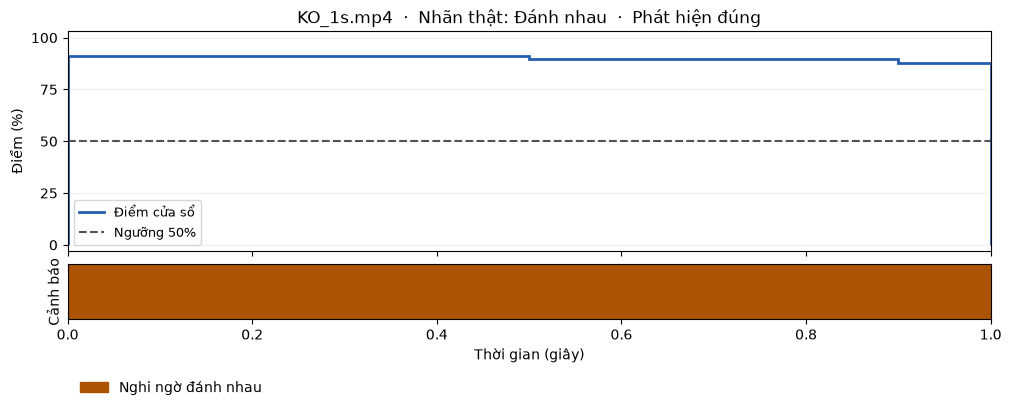

,start_s,end_s,p_action,p_touch,pose_ok,decision
16,0.4,1.4,0.951172,0.271,False,suspected


,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
KO3_2s.mp4,Đánh nhau,Nghi ngờ đánh nhau,Phát hiện đúng


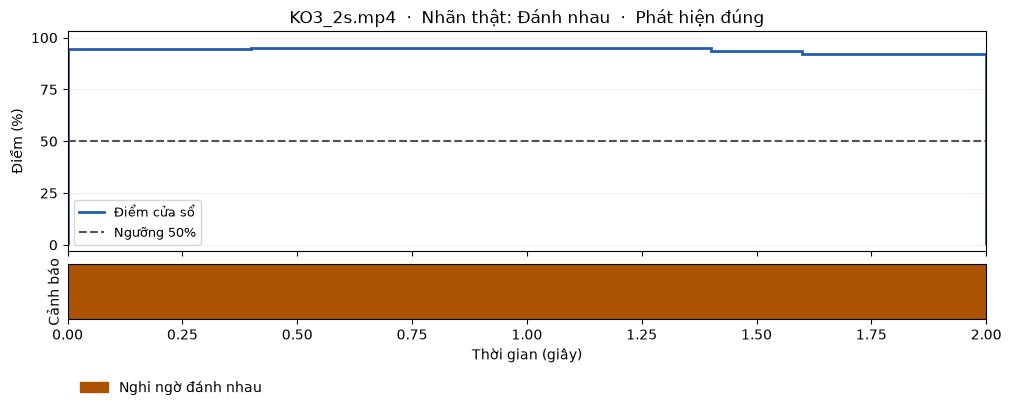

,start_s,end_s,p_action,p_touch,pose_ok,decision
40,0.0,2.4,0.963867,0.2393,False,suspected


,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
KO4_dai.mp4,Đánh nhau,Nghi ngờ đánh nhau,Phát hiện đúng


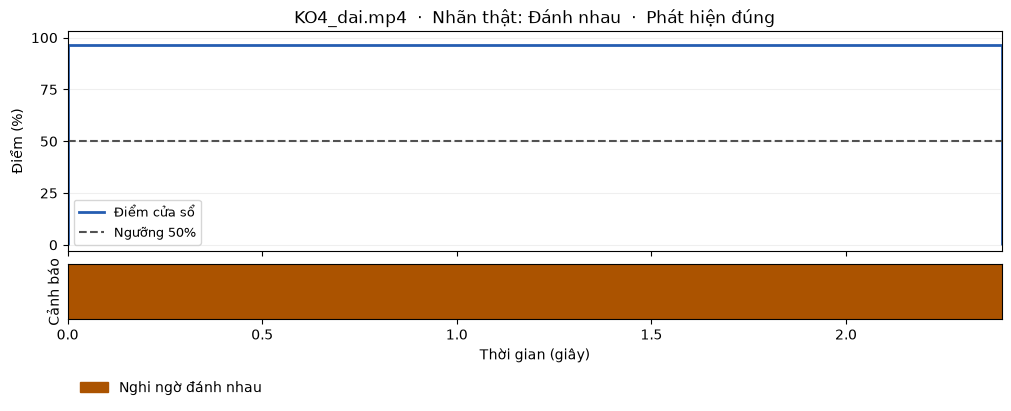

,start_s,end_s,p_action,p_touch,pose_ok,decision
146,2.8,5.8,0.888672,0.3352,False,suspected


,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
KO.mp4,Đánh nhau,Nghi ngờ đánh nhau,Phát hiện đúng


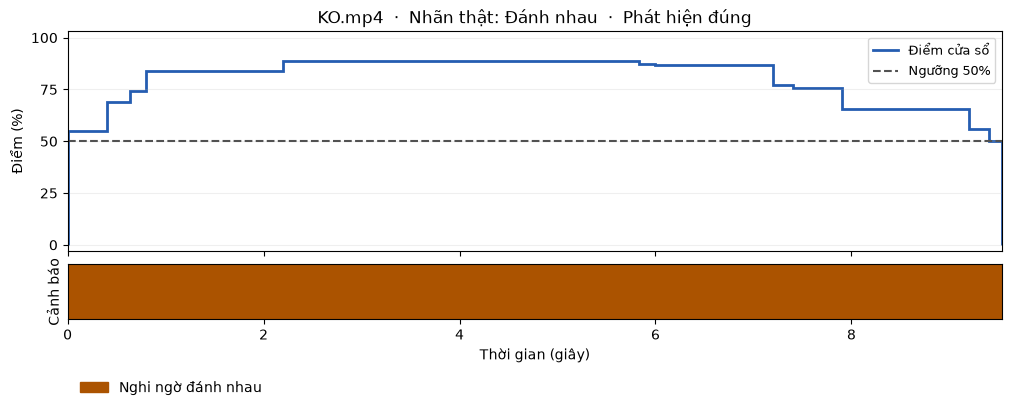

,path,decision,số cửa sổ
0,D:\TaiLieu\2026-2027\ATTT\KO.mp4,normal,17
1,D:\TaiLieu\2026-2027\ATTT\KO.mp4,suspected,108
2,D:\TaiLieu\2026-2027\ATTT\KO3_2s.mp4,suspected,16
3,D:\TaiLieu\2026-2027\ATTT\KO4_dai.mp4,suspected,20
4,D:\TaiLieu\2026-2027\ATTT\KO_1s.mp4,suspected,5


In [7]:
VIDEOS = [DATA_ROOT/name for name in ('KO_1s.mp4','KO3_2s.mp4','KO4_dai.mp4','KO.mp4')]
KO_TRUTH = {DATA_ROOT / name: 'Đánh nhau' for name in ('KO_1s.mp4','KO3_2s.mp4','KO4_dai.mp4','KO.mp4')}
results = []
for video in VIDEOS:
    print(Path(video).name)
    result = scan_video(video)
    display(result.nlargest(1,'p_action')[['start_s','end_s','p_action','p_touch','pose_ok','decision']])
    present(video,result,KO_TRUTH.get(Path(video)))
    results.append(result)
windows = pd.concat(results, ignore_index=True)
display(windows.groupby(['path','decision']).size().rename('số cửa sổ').reset_index())

## Video minh họa từ hai bộ test
Mỗi bộ gồm hai video mỗi lớp. Điểm cả clip dùng để tính chỉ số test. Đồ thị và nhãn trên video dùng cửa sổ cục bộ 3 giây, bước 1 giây.

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
NV_177.mp4,Bình thường,Bình thường,Đúng bình thường


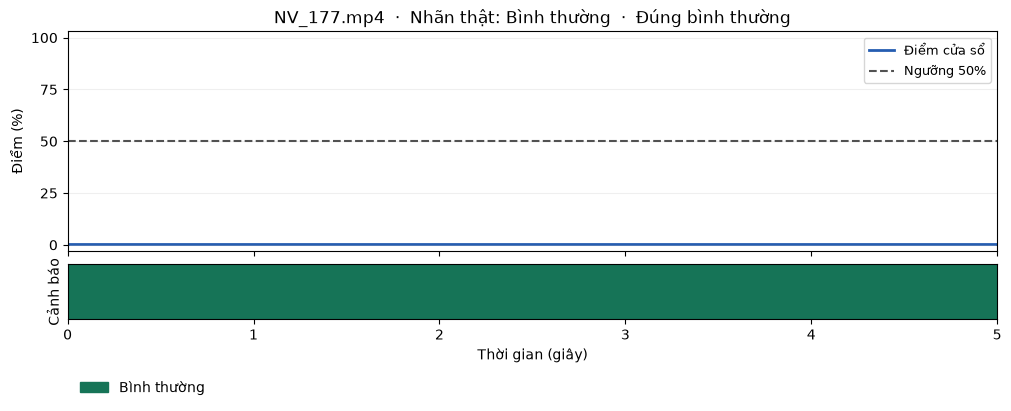

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
NV_870.avi,Bình thường,Bình thường,Đúng bình thường


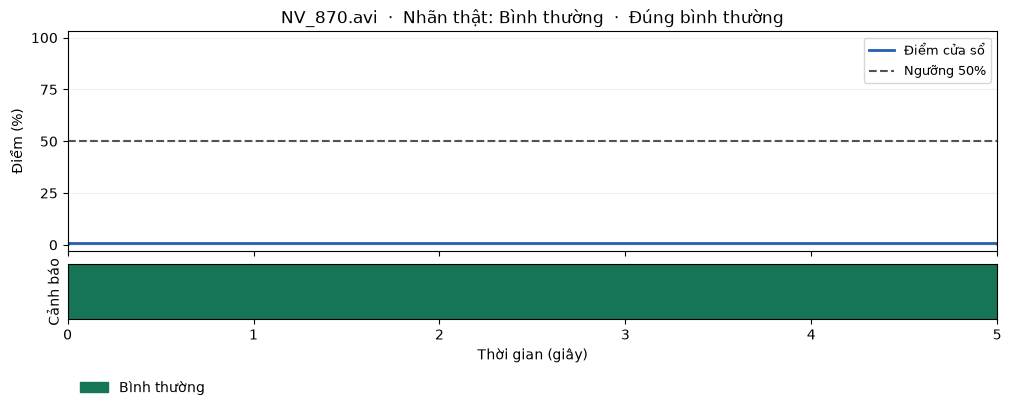

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
V_161.mp4,Đánh nhau,Nghi ngờ đánh nhau,Phát hiện đúng


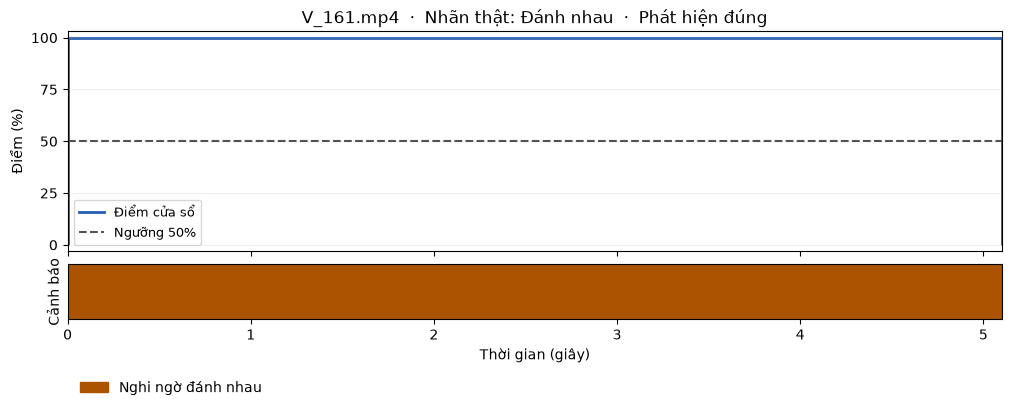

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
V_865.mp4,Đánh nhau,Nghi ngờ đánh nhau,Phát hiện đúng


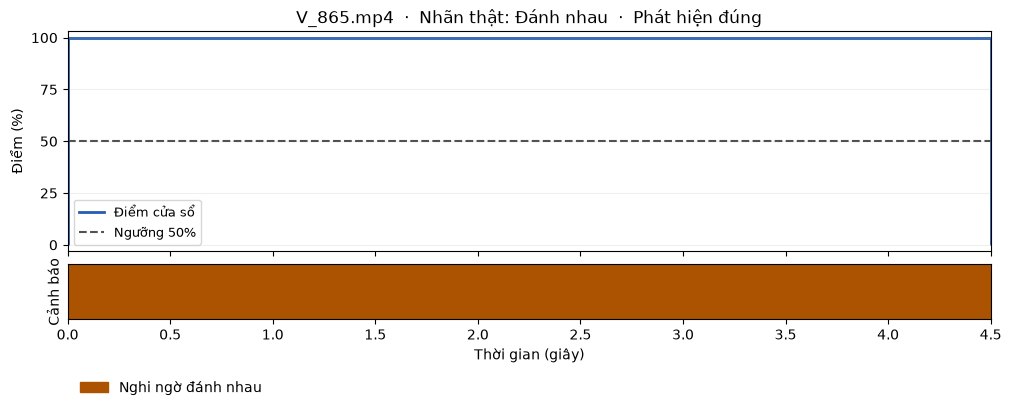

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
no379_xvid.avi,Bình thường,Nghi ngờ đánh nhau,Báo nhầm


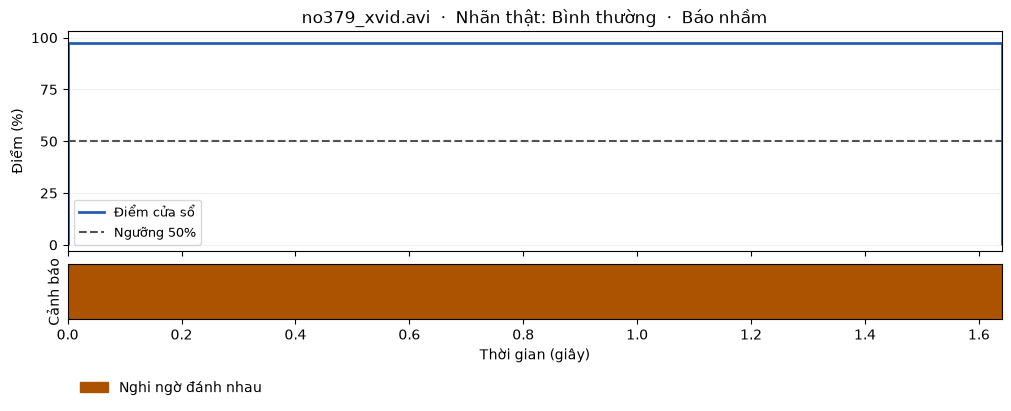

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
no112_xvid.avi,Bình thường,Nghi ngờ đánh nhau,Báo nhầm


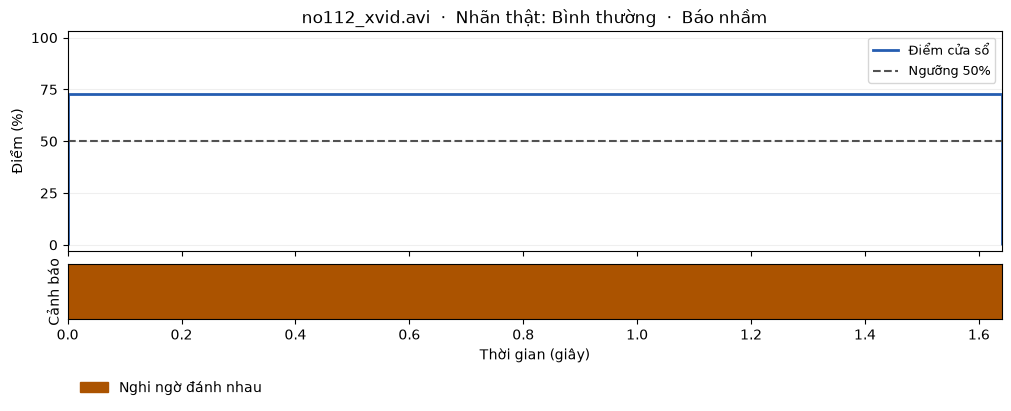

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
fi379_xvid.avi,Đánh nhau,Nghi ngờ đánh nhau,Phát hiện đúng


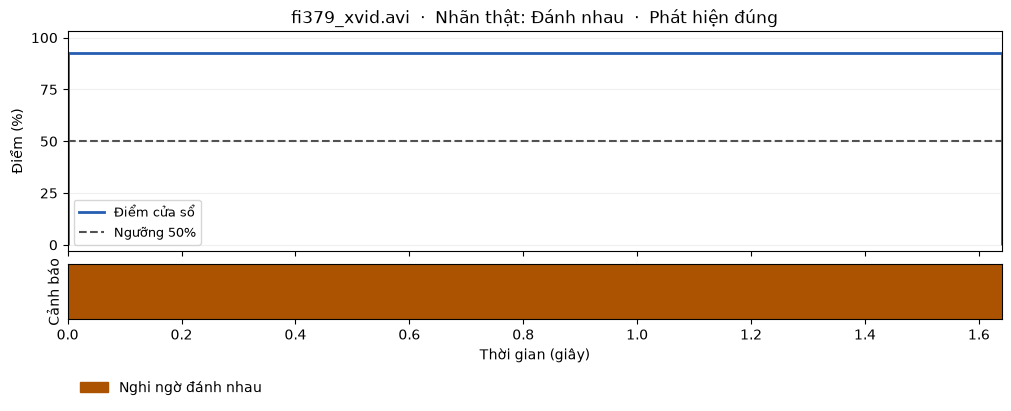

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
fi112_xvid.avi,Đánh nhau,Nghi ngờ đánh nhau,Phát hiện đúng


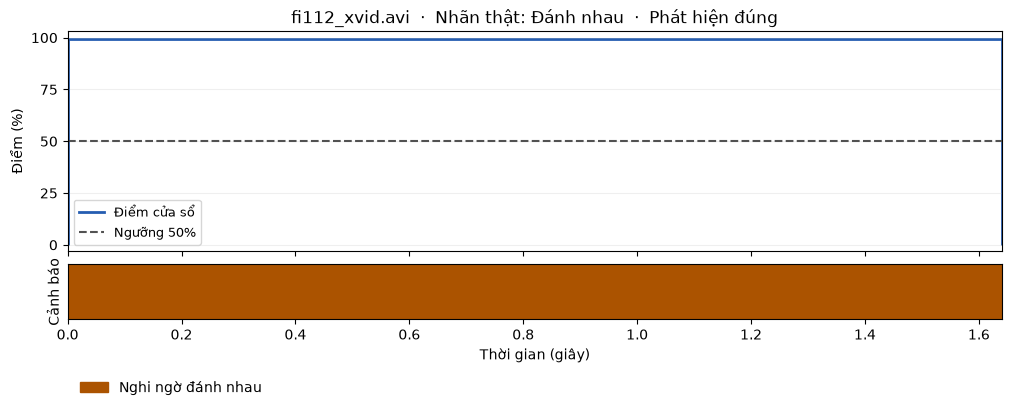

In [8]:
for name, df in [('RLVS',rlvs),('Hockey',hockey)]:
    print(name)
    for label in (0,1):
        for row in df[df.y.eq(label)].sample(2,random_state=7).itertuples():
            present_base(row)

## Xem lại các lỗi trên Hockey
Ưu tiên tối đa ba video báo nhầm điểm cao và hai video bỏ sót điểm thấp.

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
no415_xvid.avi,Bình thường,Nghi ngờ đánh nhau,Báo nhầm


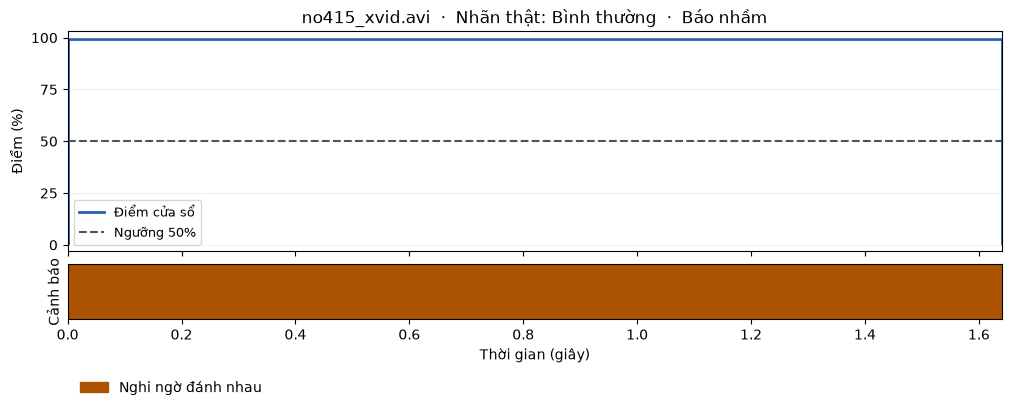

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
no379_xvid.avi,Bình thường,Nghi ngờ đánh nhau,Báo nhầm


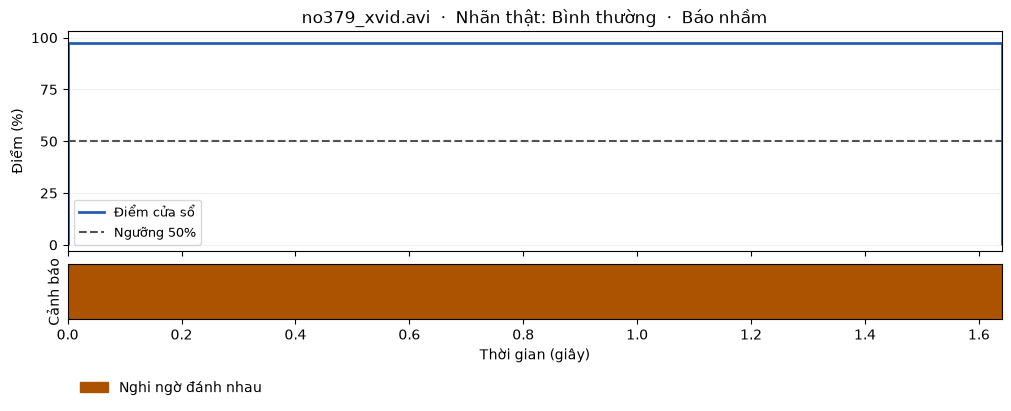

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
no306_xvid.avi,Bình thường,Nghi ngờ đánh nhau,Báo nhầm


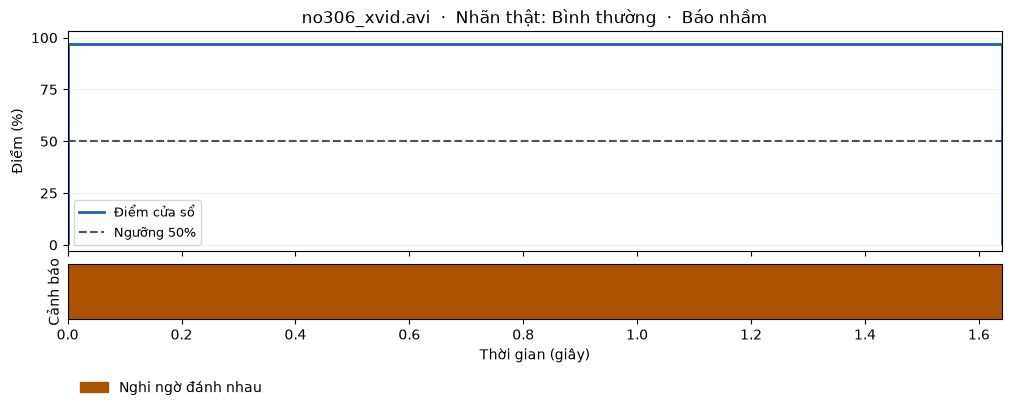

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
fi387_xvid.avi,Đánh nhau,Bình thường,Bỏ sót


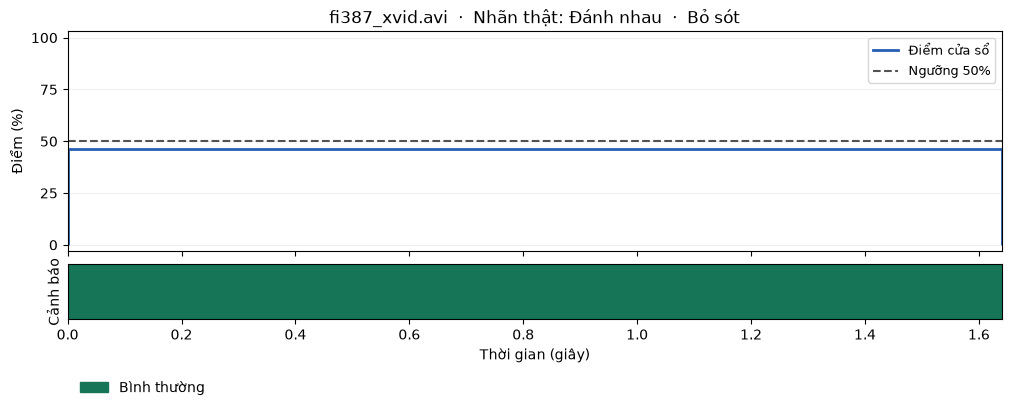

,Nhãn thật (clip),Nhãn cảnh báo,Đối chiếu
Video,,,
fi32_xvid.avi,Đánh nhau,Bình thường,Bỏ sót


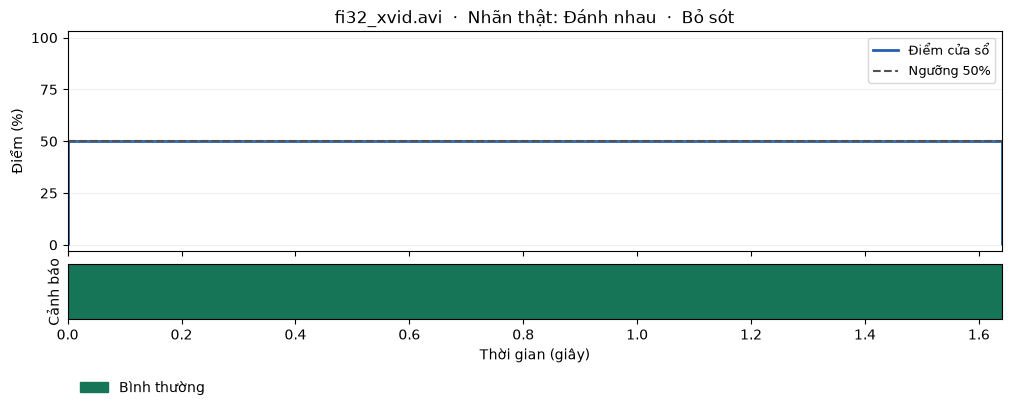

In [9]:
threshold=policy['action_threshold']
for title, subset in [('Báo nhầm',hockey[hockey.y.eq(0)&hockey.p_action.ge(threshold)].nlargest(3,'p_action')),
                      ('Bỏ sót',hockey[hockey.y.eq(1)&hockey.p_action.lt(threshold)].nsmallest(2,'p_action'))]:
    print(title, '· số ví dụ:',len(subset))
    for row in subset.itertuples():
        present_base(row)